In [1]:
import pandas as pd
import numpy as np
from utils.eval_tools import compare_models, bootstrap_compare, compare_by_segment, plot_comparison, plot_segments, plot_bootstrap
from models.popularity import PopularityModel
from models.trend_popularity import TrendPopularityModel
from utils.load_splits import load_splits
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

In [2]:
train_raw, val_raw, test_raw=load_splits(
    train_path="../../data/split/train.parquet",
    val_path="../../data/split/val.parquet",
    test_path="../../data/split/test.parquet",
)

train = train_raw[train_raw['sales_channel_id']==2]
val = val_raw[val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]

### **MODEL INIT**

In [3]:
models={
    "popularity": PopularityModel(),
    "pop_7day": PopularityModel(window_days=7),
    "trend_7day": TrendPopularityModel(window_days=7, epsilon=50, alpha=1, beta=1),
}

In [4]:
summary, per_user=compare_models(models, history_df=train, target_df=val, baseline="popularity", problem="cold_start")

Setup: user_group=cold, truth_mode=all -> 972 users, 2,666 relevant purchases
        12.5% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating popularity ...
Evaluating pop_7day ...
Evaluating trend_7day ...


In [5]:
ci_df, paired_df=bootstrap_compare(per_user, baseline="popularity", k=12)

In [6]:
summary.to_csv("results/model_comparison.csv")
paired_df.to_csv("results/paired_ci_df.csv")

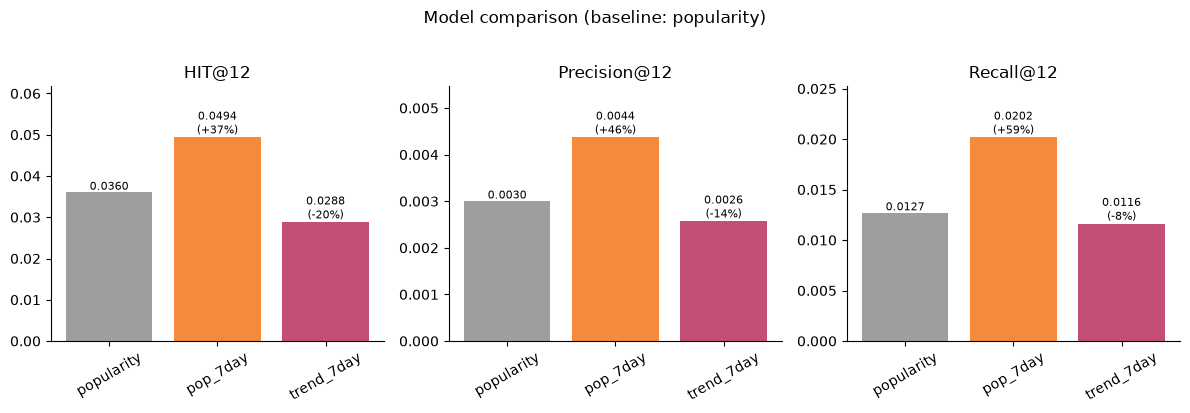

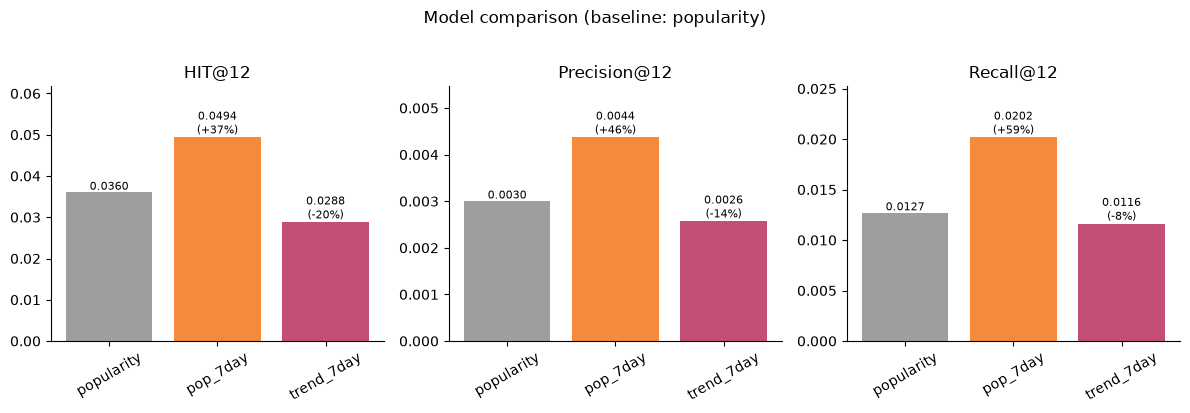

In [14]:
plot_comparison(summary,baseline="popularity", k=12)

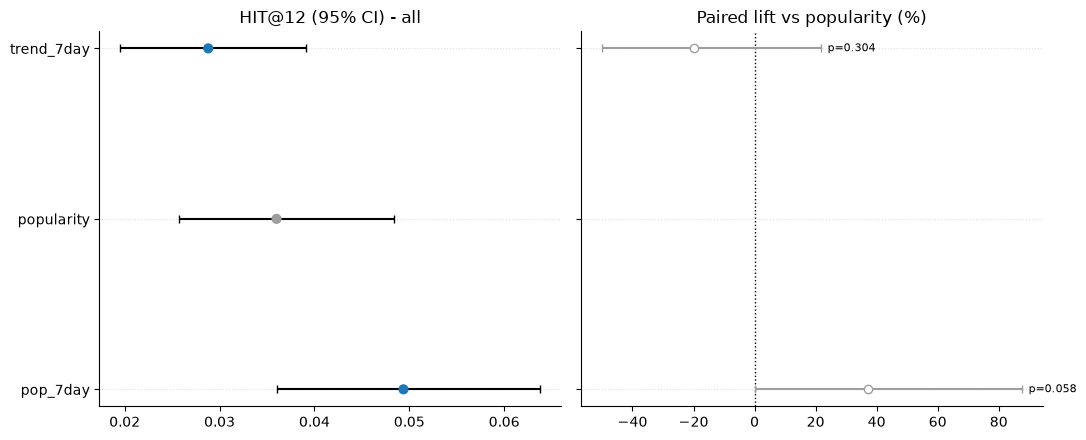

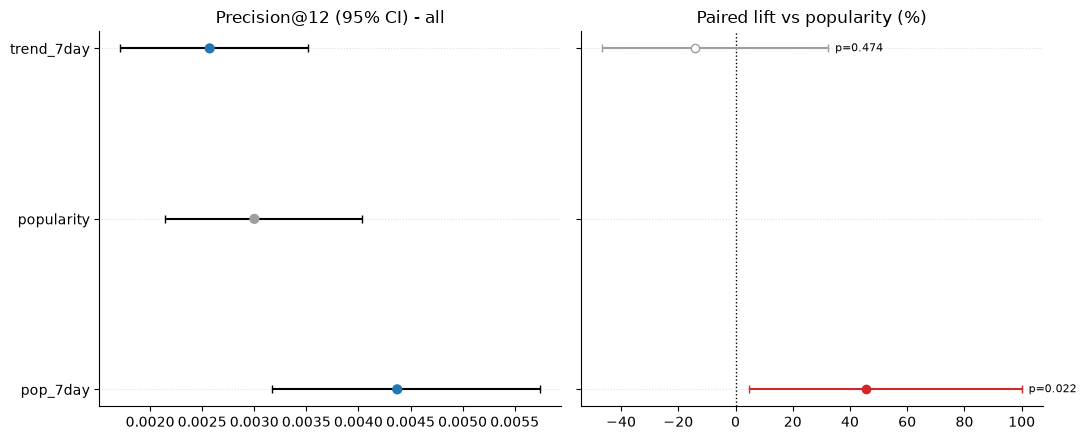

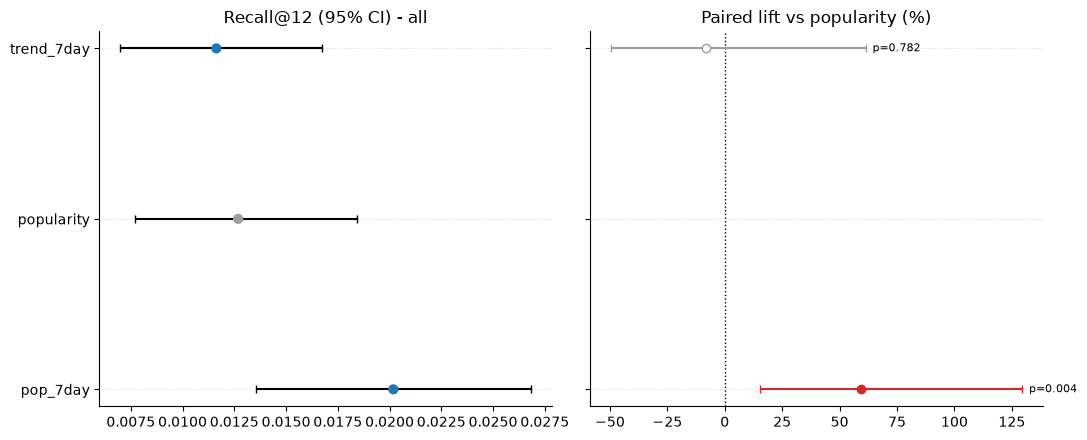

In [18]:
metrics=["HIT@12", "Precision@12", "Recall@12"]
for m in metrics:
    plot_bootstrap(ci_df, paired_df, baseline="popularity", metric=m, save_path=f"figures/ci_paired_ci_{m}@12")

### **CONCLUSION**
- POP-RECENT: significant with a time window = 7 in terms of precision and recall -> selected => understand why HIT don't match -> my theory is that because the data is too small
- TREND-WEIGHTED: not significant => needs investigation - tuning among betas => to see the effect of trend score and EDA to find out why?

Next steps:
- EDA & Result analysis

Setup: user_group=cold, truth_mode=all -> 972 users, 2,666 relevant purchases
        12.5% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating pop_7day ...
Evaluating trend_b0.25 ...
Evaluating trend_b0.5 ...
Evaluating trend_b1 ...
Evaluating trend_b2 ...
Evaluating trend_b4 ...


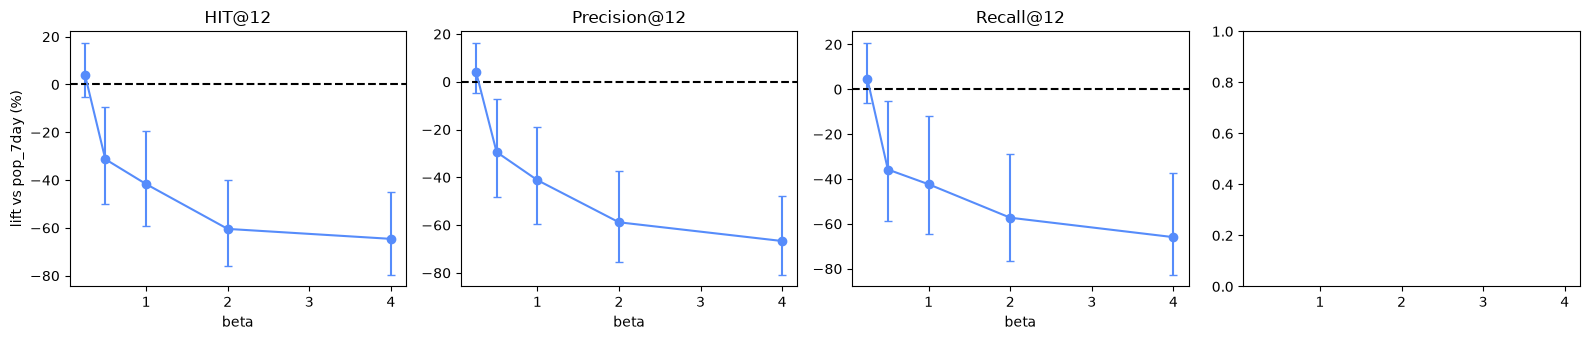

In [20]:
# case 1: window_days = 7 and beta increasing
# beta as [0.25, 0.5, 1, 2, 4]
# beta = 1 -> should yield result as popularity
betas = [0.25, 0.5, 1, 2, 4]
models_v2 = {"pop_7day": PopularityModel(window_days=7)}
models_v2.update({f"trend_b{b}": TrendPopularityModel(window_days=7, alpha=1, beta=b) for b in betas})

summary, per_user = compare_models(models_v2, train, val, baseline="pop_7day", problem="cold_start")
ci_df, paired_df = bootstrap_compare(per_user, baseline="pop_7day", n_boot=2000) #n_boot more for more reliable results

sweep = paired_df.assign(beta=lambda d: d["model"].str.extract(r"b([\d.]+)")[0].astype(float))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, metric in zip(axes, ["HIT@12", "Precision@12", "Recall@12"]):
    d = sweep[(sweep["segment"] == "all") & (sweep["metric"] == metric)].sort_values("beta")
    ax.errorbar(d["beta"], d["lift_pct"],
                yerr=[d["lift_pct"] - d["lift_low"], d["lift_high"] - d["lift_pct"]],
                fmt="o-", capsize=3)
    ax.axhline(0, ls="--", c="k")
    ax.set_title(metric)
    ax.set_xlabel("beta")
axes[0].set_ylabel("lift vs pop_7day (%)")
plt.tight_layout()

A trend that if beta increases the model performs worse across each accuracy metric => try lower the beta range then extend the window day

Setup: user_group=cold, truth_mode=all -> 972 users, 2,666 relevant purchases
        12.5% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating pop_7day ...
Evaluating trend_b0.01 ...
Evaluating trend_b0.05 ...
Evaluating trend_b0.1 ...


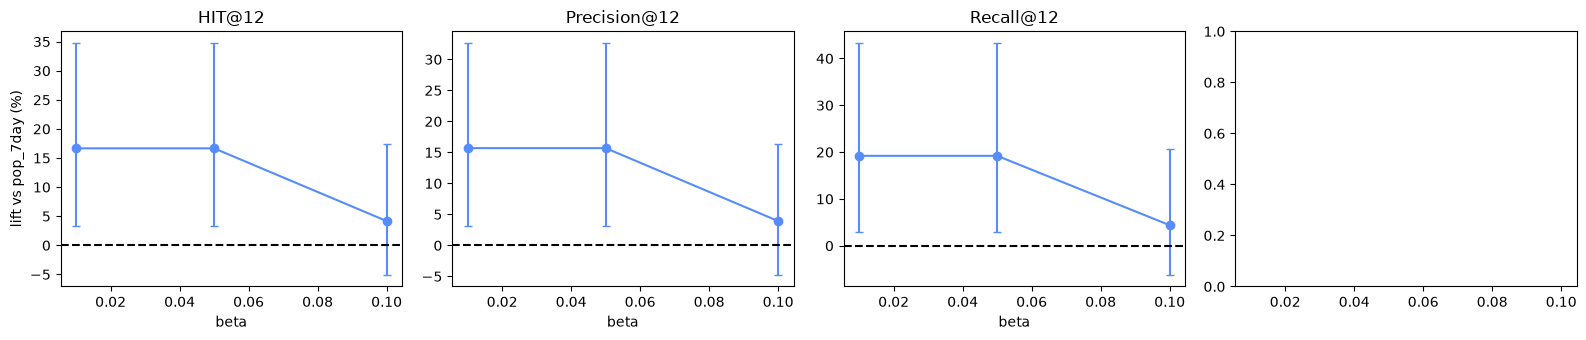

In [21]:
# case 1: window_days = 7 and beta increasing
# beta as [0.01, 0.05, 0.1]
betas = [0.01, 0.05, 0.1]
models_v3 = {"pop_7day": PopularityModel(window_days=7)}
models_v3.update({f"trend_b{b}": TrendPopularityModel(window_days=7, alpha=1, beta=b) for b in betas})

summary, per_user = compare_models(models_v3, train, val, baseline="pop_7day", problem="cold_start")
ci_df, paired_df = bootstrap_compare(per_user, baseline="pop_7day", n_boot=2000) #n_boot more for more reliable results

sweep = paired_df.assign(beta=lambda d: d["model"].str.extract(r"b([\d.]+)")[0].astype(float))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, metric in zip(axes, ["HIT@12", "Precision@12", "Recall@12"]):
    d = sweep[(sweep["segment"] == "all") & (sweep["metric"] == metric)].sort_values("beta")
    ax.errorbar(d["beta"], d["lift_pct"],
                yerr=[d["lift_pct"] - d["lift_low"], d["lift_high"] - d["lift_pct"]],
                fmt="o-", capsize=3)
    ax.axhline(0, ls="--", c="k")
    ax.set_title(metric)
    ax.set_xlabel("beta")
axes[0].set_ylabel("lift vs pop_7day (%)")
plt.tight_layout()

A positive result has shown up -> however this will put some concerns over why this happens, and when this happens, is it truly significant or just random noise?

But the beta at **0.01 and 0.05 give identical results**. That suggests the top-12 lists are the same, so beta at those values changes almost nothing => so the model might be converging into the recent_popularity with the exact window_day = 7

Let's try expanding the window day

Setup: user_group=cold, truth_mode=all -> 972 users, 2,666 relevant purchases
        12.5% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating pop_7day ...
Evaluating trend_b0.01 ...
Evaluating trend_b0.05 ...
Evaluating trend_b0.1 ...


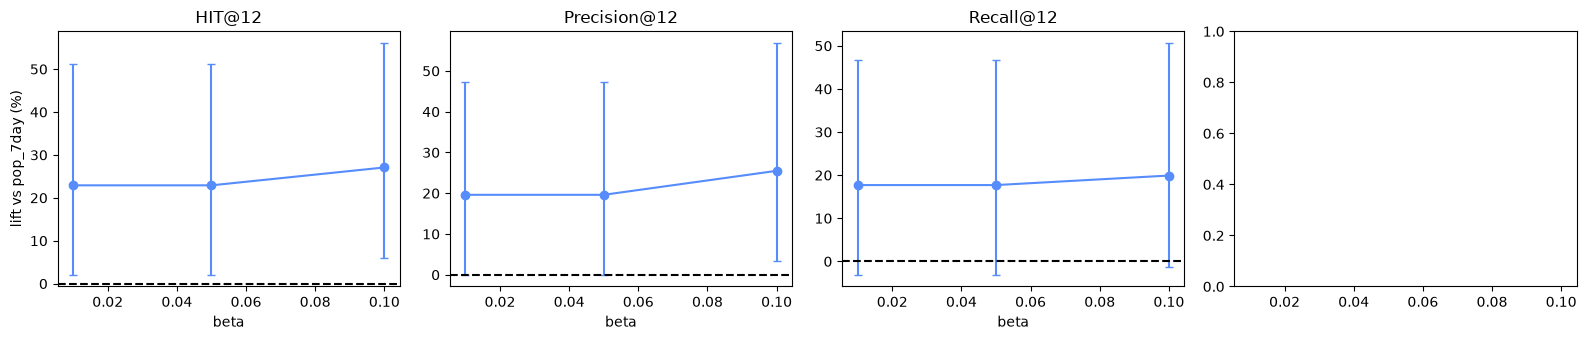

In [24]:
# case 1: window_days = 7 and beta increasing
# beta as [0.01, 0.05, 0.1]
betas = [0.01, 0.05, 0.1]
models_v3 = {"pop_7day": PopularityModel(window_days=7)}
models_v3.update({f"trend_b{b}": TrendPopularityModel(window_days=35, alpha=1, beta=b) for b in betas})

summary, per_user = compare_models(models_v3, train, val, baseline="pop_7day", problem="cold_start")
ci_df, paired_df = bootstrap_compare(per_user, baseline="pop_7day", n_boot=2000) #n_boot more for more reliable results

sweep = paired_df.assign(beta=lambda d: d["model"].str.extract(r"b([\d.]+)")[0].astype(float))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, metric in zip(axes, ["HIT@12", "Precision@12", "Recall@12"]):
    d = sweep[(sweep["segment"] == "all") & (sweep["metric"] == metric)].sort_values("beta")
    ax.errorbar(d["beta"], d["lift_pct"],
                yerr=[d["lift_pct"] - d["lift_low"], d["lift_high"] - d["lift_pct"]],
                fmt="o-", capsize=3)
    ax.axhline(0, ls="--", c="k")
    ax.set_title(metric)
    ax.set_xlabel("beta")
axes[0].set_ylabel("lift vs pop_7day (%)")
plt.tight_layout()

I have tested 3 times with different windows day -> but I don't see much change, it seems quite consistent

My final confusion is that whether the "trend signal" gives anything -> I'll run it at beta=0 to see it

Setup: user_group=cold, truth_mode=all -> 972 users, 2,666 relevant purchases
        12.5% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating pop_7day ...
Evaluating trend_b0 ...


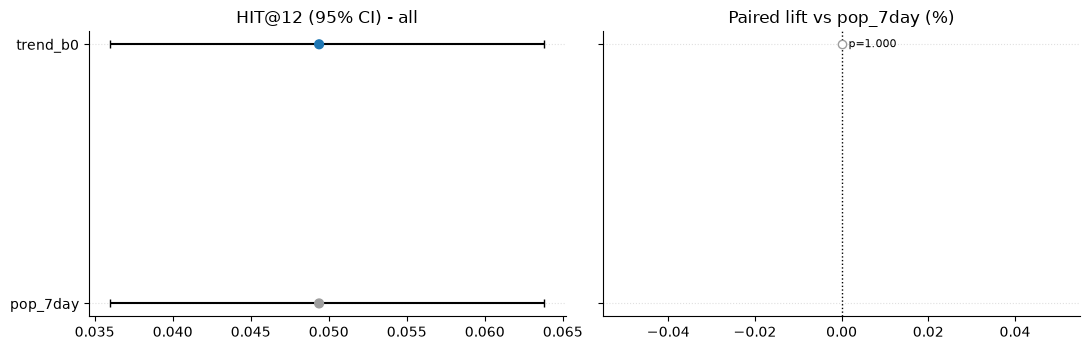

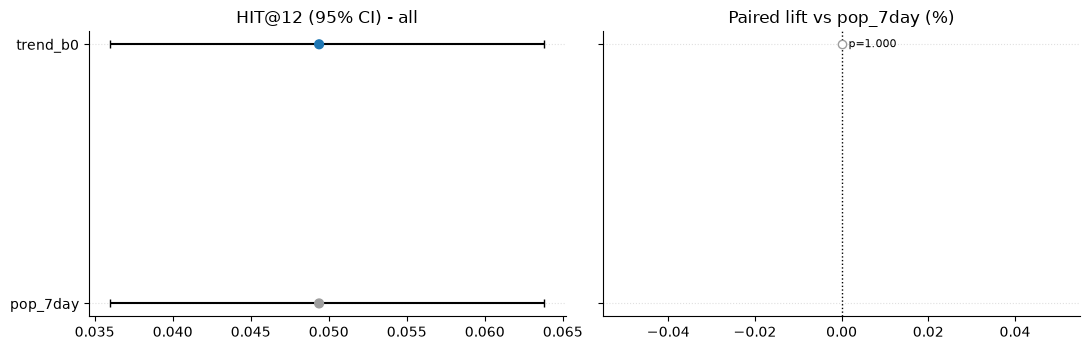

In [26]:
models_v4={
    "pop_7day": PopularityModel(window_days=7),
    "trend_b0": TrendPopularityModel(window_days=7, alpha=1, beta=0),
}

summary, per_user = compare_models(models_v4, train, val, baseline="pop_7day", problem="cold_start")
ci_df, paired_df = bootstrap_compare(per_user, baseline="pop_7day", n_boot=2000) #n_boot more for more reliable results

plot_bootstrap(ci_df, paired_df, baseline="pop_7day", metric="HIT@12")

trend_b0 is identical to pop_7day (lift 0, p=1.0), so the model reproduces the baseline at beta=0. That means the +17% at beta=0.01–0.05 does come from the tiny trend, with window day hold constant at 7 days

In [28]:
# EDA
# Is the model just recent popularity?
def q1_top_k_overlap(history_df, anchor_date, model_cls, betas=(0.01, 0.05, 0.1, 0.5, 1.0),
                     k=12, **model_kwargs):
    """How many of the top-k articles differ from the pure recent-popularity list (beta=0)?

    model_cls    : TrendPopularityModel
    model_kwargs : same settings you tuned with (window_days, epsilon, normalize, ...);
                   do NOT pass alpha/beta/k/exclude_seen (set here).
    Returns one row per beta: n_same, n_changed, and which articles entered/left.
    """
    def top(beta):
        m = model_cls(alpha=1.0, beta=beta, k=k, exclude_seen=False, **model_kwargs)
        m.fit(history_df, anchor_date)
        return list(m.ranking_["article_id"].head(k))

    base = top(0.0)
    rows = []
    for b in betas:
        cur = top(b)
        rows.append({
            "beta": b,
            "n_same": len(set(base) & set(cur)),
            "n_changed": k - len(set(base) & set(cur)),
            "entered": sorted(set(cur) - set(base)),
            "left": sorted(set(base) - set(cur)),
        })
    return pd.DataFrame(rows)

anchor_date=val_raw['t_dat'].min()
q1_top_k_overlap(train, anchor_date, TrendPopularityModel, window_days=7, epsilon=50)

,beta,n_same,n_changed,entered,left
0,0.01,11,1,[0751471043],[0915526002]
1,0.05,11,1,[0751471043],[0915526002]
2,0.10,11,1,[0877769001],[0915526002]
3,0.50,8,4,"[0863583002, 0877769001, 0903309001, 0914441004]","[0448509014, 0706016003, 0751471001, 0915526002]"
4,1.00,7,5,"[0863583002, 0877769001, 0903309001, 091444100...","[0448509014, 0706016003, 0751471001, 075803400..."


In [30]:
# Does trend predict future sales?
def q2_trend_predictiveness(history_df, future_df, anchor_date, window_days=7,
                            epsilon=50, min_recent=1, top_n=500):
    """Does trend T (or volume R) at the anchor predict the future?

    Compares per article:
      R = recent-window sales, P = previous-window sales, T = (R-P)/(P+epsilon)
      F = sales in future_df (rescaled to one window so it is comparable to R)
    Reports Spearman correlations:
      corr(R, F)      : does volume predict future sales?   (expected: high)
      corr(T, F)      : does trend predict future sales?
      corr(T, F - R)  : does trend predict the CHANGE from R to F? (the real momentum test)
    Also repeated on the top_n articles by R, which is the pool the model actually ranks.
    """
    w = pd.Timedelta(days=window_days)
    h = history_df[history_df["t_dat"] >= anchor_date - 2 * w]
    recent = h[h["t_dat"] >= anchor_date - w].groupby("article_id").size().rename("R")
    prev = h[h["t_dat"] < anchor_date - w].groupby("article_id").size().rename("P")

    future_days = max((future_df["t_dat"].max() - future_df["t_dat"].min()).days + 1, 1)
    fut = future_df.groupby("article_id").size().rename("F") * (window_days / future_days)

    t = pd.concat([recent, prev, fut], axis=1).fillna(0)
    t["T"] = (t["R"] - t["P"]) / (t["P"] + epsilon)
    t["dF"] = t["F"] - t["R"]
    t = t[t["R"] >= min_recent]

    def corr(frame, a, b):
        return spearmanr(frame[a], frame[b])[0] if len(frame) > 2 else np.nan

    out = []
    for label, frame in [("all articles", t), (f"top {top_n} by R", t.nlargest(top_n, "R"))]:
        out.append({
            "pool": label, "n_articles": len(frame),
            "corr_R_vs_F": corr(frame, "R", "F"),
            "corr_T_vs_F": corr(frame, "T", "F"),
            "corr_T_vs_change": corr(frame, "T", "dF"),
        })
    return pd.DataFrame(out)


In [31]:
q2_trend_predictiveness(train, val, anchor_date)

,pool,n_articles,corr_R_vs_F,corr_T_vs_F,corr_T_vs_change
0,all articles,5510,0.572680,0.053385,-0.155793
1,top 500 by R,500,0.450029,0.194866,-0.169030


In [32]:
# Does growth persist week to week?
def q3_momentum_persistence(history_df, anchor_date, window_days=7, n_weeks=8,
                            epsilon=50, min_volume=10):
    """Does an article's growth in one period persist into the next?

    Splits the last n_weeks (window_days each) before the anchor into periods, computes growth
    g_w = (c_w - c_{w-1}) / (c_{w-1} + epsilon) per article, and correlates g_w with g_{w+1}
    (Spearman) across articles, for each consecutive pair, keeping articles with at least
    min_volume sales over the 3 periods involved.
    Returns one row per pair + the mean (last row).
    """
    w = pd.Timedelta(days=window_days)
    start = anchor_date - n_weeks * w
    h = history_df[history_df["t_dat"] >= start].copy()
    h["period"] = ((h["t_dat"] - start) // w).astype(int).clip(upper=n_weeks - 1)
    counts = h.groupby(["article_id", "period"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=range(n_weeks), fill_value=0)

    rows = []
    for p in range(1, n_weeks - 1):
        c0, c1, c2 = counts[p - 1], counts[p], counts[p + 1]
        keep = (c0 + c1 + c2) >= min_volume
        g1 = (c1 - c0) / (c0 + epsilon)
        g2 = (c2 - c1) / (c1 + epsilon)
        if keep.sum() > 2:
            rows.append({"pair": f"g{p} -> g{p + 1}", "n_articles": int(keep.sum()),
                         "spearman": spearmanr(g1[keep], g2[keep])[0]})
    res = pd.DataFrame(rows)
    res.loc[len(res)] = {"pair": "MEAN", "n_articles": int(res["n_articles"].mean()),
                         "spearman": res["spearman"].mean()}
    return res

In [33]:
q3_momentum_persistence(train, anchor_date)

,pair,n_articles,spearman
0,g1 -> g2,1574,-0.302921
1,g2 -> g3,1480,-0.262734
2,g3 -> g4,1557,-0.360429
3,g4 -> g5,1627,-0.258122
4,g5 -> g6,1609,-0.297445
5,g6 -> g7,1496,-0.042241
6,MEAN,1557,-0.253982


### **CONCLUSION FOR TREND**
* Q1: Only 1/12 item gets changed (at low beta) => works similarly to recent popularity that even adds more noise when beta increases
* Q2: `corr_T_vs_change` & `corr_T_vs_F` exhibits that trend signal itself is a weak & even "mean-reversion" compared to ($R$)
* Q3: MEAN spearman lands at -0.25 -> no momentum

The data exhibits mean reversion rather than sales momentum across all validation checks. Baseline recent volume ($R$) remains the primary predictor of future sales ($corr(R, F) = 0.45\text{--}0.57$). In contrast, trend momentum shows a negative correlation with future change ($corr(T, \Delta) \approx -0.16$) and week-over-week growth exhibits persistent negative rank correlation (mean Spearman $\rho = -0.254$). Consequently, setting high trend weight ($\beta \ge 0.50$) introduces noise by replacing stable top sellers with transient spikes, whereas small $\beta$ values ($0.01\text{--}0.05$) merely replicate recent popularity with a single item swap. Trend-based re-ranking hurts predictive accuracy in this domain.

BUT WHY?

### **LIMITATIONS**
* Q3’s mean of weekly correlations is a rough summary, not a tested estimate. Quote it as “about X, typically negative/positive” and don’t attach p-values.
* Q2 rescales future sales to one window length so they compare with R. If your test window is very short, the correlations are noisy.
* On the 10% sample, small counts make all three correlations noisy and probably biased towards negative -> which drives the inconsistency in pop_recent_7day

In [34]:
#final EDA
# null: each article's weekly count ~ Poisson(its own average); same Spearman as Q3
def q3_null(counts, eps=50, min_volume=10, seed=0):
    """counts: DataFrame articles x weeks (the matrix inside q3_momentum_persistence)."""
    rng = np.random.default_rng(seed)
    sim = rng.poisson(counts.mean(axis=1).to_numpy()[:, None], size=counts.shape)
    rho = []
    for p in range(1, sim.shape[1] - 1):
        c0, c1, c2 = sim[:, p-1], sim[:, p], sim[:, p+1]
        keep = (c0 + c1 + c2) >= min_volume
        rho.append(spearmanr(((c1-c0)/(c0+eps))[keep], ((c2-c1)/(c1+eps))[keep])[0])
    return np.mean(rho)

w = pd.Timedelta(days=7)
start = anchor_date - 8 * w
h = train[train["t_dat"] >= start].copy()
h["period"] = ((h["t_dat"] - start) // w).astype(int).clip(upper=8 - 1)
counts = h.groupby(["article_id", "period"]).size().unstack(fill_value=0)
counts = counts.reindex(columns=range(8), fill_value=0)

q3_null(counts)

np.float64(-0.480993222086551)